In [1]:
!pip install langgraph langsmith langchain langchain_groq langchain_community

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 591.4/591.4 kB 18.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 70.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 42.7 MB/s  0:00:00
  Attempting uninstall: requests
    Found existing installation: requests 2.32.4
    Uninstalling requests-2.32.4:
      Successfully uninstalled requests-2.32.4
  Attempting uninstall: langchain-protocol
    Found existing installation: langchain-protocol 0.0.20
    Uninstalling langchain-protocol-0.0.20:
      Successfully uninstalled langchain-protocol-0.0.20
  Attempting uninstall: langchain-core
    Found existing installation: langchain-core 1.7.4
    Uninstalling langchain-core-1.7.4:
      Successfully uninstalled langchain-core-1.7.4
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10/10 [langchain_community]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following

In [2]:
from typing import Annotated
from typing_extensions import TypedDict

In [3]:
!pip install wikipedia
!pip install "arxiv<2.0.0"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for wikipedia: filename=wikipedia-1.4.0-py3-none-any.whl size=11757 sha256=22a025ade99b6bd1ec07af56a247094c55e38d45c8c3edcbf898d26641f4d9e5
  Stored in directory: /root/.cache/pip/wheels/79/1d/c8/b64e19423cc5a2a339450ea5d145e7c8eb3d4aa2b150cde33b
Successfully built wikipedia
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [arxiv]


In [4]:
import sys
try:
    import cgi
except ImportError:
    import html
    import types
    # Create a minimal mock of cgi module for feedparser
    cgi = types.ModuleType("cgi")
    cgi.escape = html.escape
    sys.modules["cgi"] = cgi

from langchain_community.utilities import ArxivAPIWrapper, WikipediaAPIWrapper
from langchain_community.tools import ArxivQueryRun, WikipediaQueryRun

## Arxiv And Wikipedia tools
arxiv_wrapper = ArxivAPIWrapper(top_k_results=1, doc_content_chars_max=300)
arxiv_tool = ArxivQueryRun(api_wrapper=arxiv_wrapper)

api_wrapper = WikipediaAPIWrapper(top_k_results=1, doc_content_chars_max=300)
wiki_tool = WikipediaQueryRun(api_wrapper=api_wrapper)

/tmp/ipykernel_1257/1868634831.py:12: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.utilities import ArxivAPIWrapper, WikipediaAPIWrapper


In [5]:
wiki_tool.invoke("who is Keerthi Suresh")

'Page: Keerthy Suresh\nSummary: Keerthy Suresh (born 17 October 1992) is an Indian actress who predominantly appears in Tamil, Telugu and Malayalam films. Her film accolades include one National Film Award, five SIIMA Awards, one Tamil Nadu State Film Award and two Filmfare Awards South. Keerthy was p'

In [6]:
wiki_tool.invoke("what is the latest hot topic running in wikipedia")

'Page: Red Hot Chili Peppers\nSummary: The Red Hot Chili Peppers are an American rock band formed in Los Angeles in 1982, consisting of Flea (bass), Anthony Kiedis (vocals), Chad Smith (drums), and John Frusciante (guitar). Their music incorporates elements of alternative rock, funk, punk rock, hard r'

In [7]:
tools=[wiki_tool]

In [8]:
## Langgraph Application
from langgraph.graph.message import add_messages
class State(TypedDict):
  messages:Annotated[list,add_messages]

In [9]:
from langgraph.graph import StateGraph,START,END

In [10]:
graph_builder= StateGraph(State)

In [11]:
from langchain_groq import ChatGroq

In [13]:
from google.colab import userdata
groq_api_key=userdata.get("GROK_API_KEY")

In [14]:
llm=ChatGroq(groq_api_key=groq_api_key,model_name="openai/gpt-oss-120b")
llm

ChatGroq(metadata={'lc_versions': {'langchain-core': '1.8.5', 'langchain': '1.4.8', 'langchain-groq': '1.2.1'}}, profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2025-08-05', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True}, client=<groq.resources.chat.completions.Completions object at 0x782b9b9f7e00>, async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x782b9b774c20>, model_name='openai/gpt-oss-120b', model_kwargs={}, groq_api_key=SecretStr('**********'))

In [15]:

llm_with_tools=llm.bind_tools(tools=tools)

In [16]:
def chatbot(state:State):
  return {"messages":[llm_with_tools.invoke(state["messages"])]}

In [18]:
from langgraph.prebuilt import ToolNode,tools_condition

In [19]:
graph_builder.add_node("chatbot",chatbot)
tool_node = ToolNode(tools=tools)
graph_builder.add_node("tools", tool_node)

graph_builder.add_conditional_edges(
    "chatbot",
    tools_condition,
)
graph_builder.add_edge("tools", "chatbot")
graph_builder.add_edge(START,"chatbot")

In [20]:
graph=graph_builder.compile()

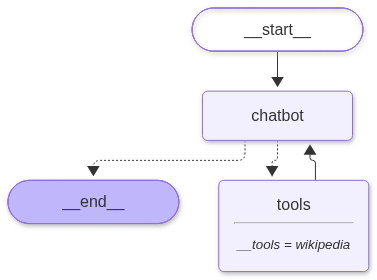

In [21]:
from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    # This requires some extra dependencies and is optional
    pass

In [22]:
user_input="Hi there!, My name is Cherry"

events=graph.stream(
     {"messages": [("user", user_input)]},stream_mode="values"
)

for event in events:
  event["messages"][-1].pretty_print()

================================ Human Message =================================

Hi there!, My name is Cherry
================================== Ai Message ==================================

Hello Cherry! 👋 Nice to meet you. I'm ChatGPT—here to help with questions, brainstorm ideas, or just chat. How can I assist you today?


In [23]:
user_input = "what is LangGraph"

# The config is the **second positional argument** to stream() or invoke()!
events = graph.stream(
    {"messages": [("user", user_input)]},stream_mode="values"
)
for event in events:
    event["messages"][-1].pretty_print()

================================ Human Message =================================

what is LangGraph
================================== Ai Message ==================================
Tool Calls:
  wikipedia (fc_1767719c-a904-44f8-9d92-99e44e73c641)
 Call ID: fc_1767719c-a904-44f8-9d92-99e44e73c641
  Args:
    query: LangGraph
================================= Tool Message =================================
Name: wikipedia

Page: LangChain
Summary: LangChain is a software framework that helps facilitate the integration of large language models (LLMs) into applications. As a language model integration framework, LangChain's use-cases largely overlap with those of language models in general, including document analysis a
================================== Ai Message ==================================
Tool Calls:
  wikipedia (fc_8ff485d2-d3a9-4225-aec2-8158f1101b58)
 Call ID: fc_8ff485d2-d3a9-4225-aec2-8158f1101b58
  Args:
    query: LangGraph LangChain
================================= Tool 

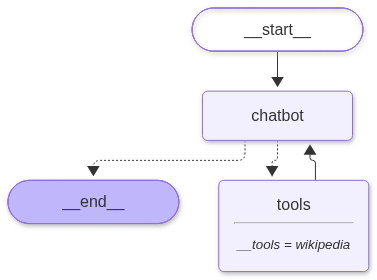

In [24]:
from IPython.display import Image, display
try:
  display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
  pass